# Loading Dataset

In [37]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [15]:
# Cell 2 – Load Dataset from Google Drive

from google.colab import drive
import os

drive.mount("/content/drive")

DATASET_PATH = (
    "/content/drive/MyDrive/"
    "IITG dataset/cleaned_dataset/processed_dataset_v1"
)

SEQUENCE_FILE = os.path.join(
    DATASET_PATH,
    "sequences_v1.npz"
)

print("Dataset path:")
print(SEQUENCE_FILE)

print("\nFile exists:", os.path.exists(SEQUENCE_FILE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset path:
/content/drive/MyDrive/IITG dataset/cleaned_dataset/processed_dataset_v1/sequences_v1.npz

File exists: True


In [16]:
# Cell 3 – Load Sequence Data

data = np.load(
    SEQUENCE_FILE,
    allow_pickle=True
)

X_sequences = data["X"]
y_soh = data["SoH"]

sequence_battery_ids = data["battery_id"]
sequence_splits = data["split"]

print("Dataset loaded successfully.\n")

print("X shape:", X_sequences.shape)
print("SoH shape:", y_soh.shape)
print("Battery ID shape:", sequence_battery_ids.shape)
print("Split shape:", sequence_splits.shape)

print("\nSplit distribution:")
print(
    pd.Series(sequence_splits).value_counts()
)

Dataset loaded successfully.

X shape: (2287, 10, 2)
SoH shape: (2287,)
Battery ID shape: (2287,)
Split shape: (2287,)

Split distribution:
train         1516
test           392
validation     379
Name: count, dtype: int64


# Normalizing

In [24]:
# Cell 4 – Normalize SoH

print("Original SoH scale")
print("------------------")
print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

# Convert SoH from 0–100 to 0–1
y_soh = y_soh / 100.0

print("\nNormalized SoH scale")
print("-------------------")
print("Minimum:", y_soh.min())
print("Maximum:", y_soh.max())
print("Mean:", y_soh.mean())

print("\nFirst 10 normalized SoH values:")
print(y_soh[:10])

Original SoH scale
------------------
Minimum: 0.0
Maximum: 100.0
Mean: 72.7266383162617

Normalized SoH scale
-------------------
Minimum: 0.0
Maximum: 1.0
Mean: 0.7272663831626169

First 10 normalized SoH values:
[0.98283094 0.98283432 0.97722285 0.97698058 0.9768127  0.97097238
 0.97070784 0.97096241 0.97122571 0.97106913]


In [25]:
# Cell 4 – Build DataLoaders

# Create masks from the split labels
train_mask = sequence_splits == "train"
val_mask = sequence_splits == "validation"
test_mask = sequence_splits == "test"

# Split the sequences
X_train = X_sequences[train_mask]
X_val = X_sequences[val_mask]
X_test = X_sequences[test_mask]

# Split the SoH targets
y_train = y_soh[train_mask]
y_val = y_soh[val_mask]
y_test = y_soh[test_mask]

print("Train:")
print("X:", X_train.shape)
print("SoH:", y_train.shape)

print("\nValidation:")
print("X:", X_val.shape)
print("SoH:", y_val.shape)

print("\nTest:")
print("X:", X_test.shape)
print("SoH:", y_test.shape)

Train:
X: (1516, 10, 2)
SoH: (1516,)

Validation:
X: (379, 10, 2)
SoH: (379,)

Test:
X: (392, 10, 2)
SoH: (392,)


In [29]:
# Cell 5 – Build DataLoaders

batch_size = 32

train_dataset = TensorDataset(
    torch.tensor(X_train, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32)
)

val_dataset = TensorDataset(
    torch.tensor(X_val, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32)
)

test_dataset = TensorDataset(
    torch.tensor(X_test, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.float32)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully.")
print("Batch size:", batch_size)

DataLoaders created successfully.
Batch size: 32


#LSTM MODEL


In [30]:
# Cell 6 – Define LSTM Model

class PrognosticLSTM(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        num_layers,
        output_dim
    ):
        super(PrognosticLSTM, self).__init__()

        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.fc1 = nn.Linear(
            hidden_dim,
            32
        )

        self.relu = nn.ReLU()

        self.fc2 = nn.Linear(
            32,
            output_dim
        )

    def forward(self, x):

        out, _ = self.lstm(x)

        # Use the final time step
        out = out[:, -1, :]

        out = self.fc1(out)

        out = self.relu(out)

        out = self.fc2(out)

        return out.squeeze(-1)


# Number of input features
input_dim = X_train.shape[2]

model = PrognosticLSTM(
    input_dim=input_dim,
    hidden_dim=64,
    num_layers=2,
    output_dim=1
).to(device)

print(model)

PrognosticLSTM(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc1): Linear(in_features=64, out_features=32, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=32, out_features=1, bias=True)
)


In [31]:
# Cell 7 – Loss Function and Optimizer

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


#Training the MODEL

In [32]:
# Cell 8 – Train LSTM Model

epochs = 30

train_losses = []
val_losses = []

best_val_loss = float("inf")
best_epoch = 0

checkpoint_path = os.path.join(
    DATASET_PATH,
    "day15_lstm_best_soh_model.pth"
)

for epoch in range(epochs):

    # =========================
    # Training
    # =========================

    model.train()

    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_X)

        loss = criterion(
            predictions,
            batch_y
        )

        loss.backward()

        optimizer.step()

        running_train_loss += (
            loss.item() * batch_X.size(0)
        )

    train_loss = (
        running_train_loss /
        len(train_loader.dataset)
    )

    # =========================
    # Validation
    # =========================

    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for batch_X, batch_y in val_loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            predictions = model(batch_X)

            loss = criterion(
                predictions,
                batch_y
            )

            running_val_loss += (
                loss.item() * batch_X.size(0)
            )

    val_loss = (
        running_val_loss /
        len(val_loader.dataset)
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # =========================
    # Save Best Model
    # =========================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            checkpoint_path
        )

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )

print("\nTraining completed.")

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

print("\nBest model saved at:")
print(checkpoint_path)

Epoch 01/30 | Train Loss: 0.230556 | Val Loss: 0.064399
Epoch 02/30 | Train Loss: 0.058047 | Val Loss: 0.054320
Epoch 03/30 | Train Loss: 0.049211 | Val Loss: 0.057442
Epoch 04/30 | Train Loss: 0.049282 | Val Loss: 0.071179
Epoch 05/30 | Train Loss: 0.048486 | Val Loss: 0.073879
Epoch 06/30 | Train Loss: 0.051177 | Val Loss: 0.083285
Epoch 07/30 | Train Loss: 0.049881 | Val Loss: 0.066671
Epoch 08/30 | Train Loss: 0.048459 | Val Loss: 0.068313
Epoch 09/30 | Train Loss: 0.048310 | Val Loss: 0.072620
Epoch 10/30 | Train Loss: 0.048155 | Val Loss: 0.074279
Epoch 11/30 | Train Loss: 0.049842 | Val Loss: 0.069702
Epoch 12/30 | Train Loss: 0.049919 | Val Loss: 0.089084
Epoch 13/30 | Train Loss: 0.048939 | Val Loss: 0.070879
Epoch 14/30 | Train Loss: 0.048129 | Val Loss: 0.059822
Epoch 15/30 | Train Loss: 0.048997 | Val Loss: 0.074969
Epoch 16/30 | Train Loss: 0.048057 | Val Loss: 0.070919
Epoch 17/30 | Train Loss: 0.048294 | Val Loss: 0.074237
Epoch 18/30 | Train Loss: 0.047318 | Val Loss: 0

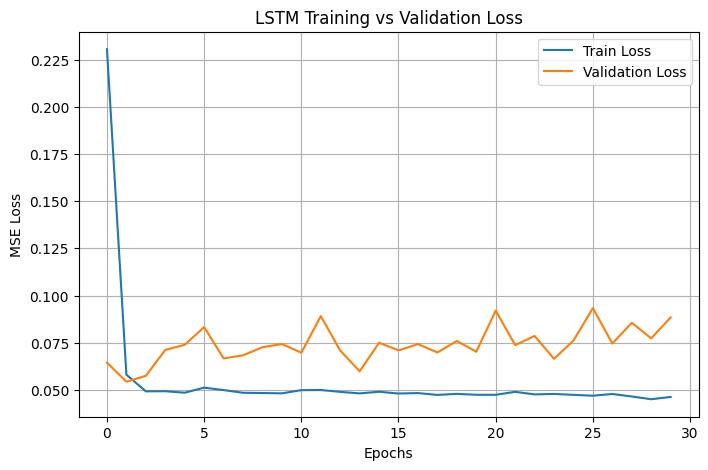

In [33]:
# Cell 9 – Training vs Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.title(
    "LSTM Training vs Validation Loss"
)

plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()

plt.grid(True)

plt.show()

# Loading the Best LSTM MODEL

In [34]:
# Cell 11 – Load Best LSTM Model

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device
    )
)

model.eval()

print("Best LSTM model loaded successfully.")
print("Best Epoch:", best_epoch)
print("Best Validation Loss:", best_val_loss)

Best LSTM model loaded successfully.
Best Epoch: 2
Best Validation Loss: 0.05431987374706444


In [35]:
# Cell 12 – Test Predictions

all_predictions = []
all_targets = []

model.eval()

with torch.no_grad():

    for batch_X, batch_y in test_loader:

        batch_X = batch_X.to(device)

        predictions = model(batch_X)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            batch_y.numpy()
        )

y_pred = np.concatenate(
    all_predictions
)

y_true = np.concatenate(
    all_targets
)

print("Test prediction completed.")

print("Actual SoH shape:", y_true.shape)
print("Predicted SoH shape:", y_pred.shape)

print("\nFirst 10 predictions:")
print(y_pred[:10])

Test prediction completed.
Actual SoH shape: (392,)
Predicted SoH shape: (392,)

First 10 predictions:
[0.6870955  0.68536127 0.6836253  0.68188775 0.68014884 0.6784085
 0.67666674 0.6749234  0.6731788  0.6714331 ]


In [38]:
# Cell 13 – Evaluation Metrics

mae = mean_absolute_error(
    y_true,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_true,
        y_pred
    )
)

mape = mean_absolute_percentage_error(
    y_true,
    y_pred
) * 100

r2 = r2_score(
    y_true,
    y_pred
)

print("LSTM Test Set Performance")
print("=" * 35)

print(f"MAE  : {mae:.6f}")
print(f"RMSE : {rmse:.6f}")
print(f"MAPE : {mape:.4f}%")
print(f"R²   : {r2:.6f}")

LSTM Test Set Performance
MAE  : 0.154379
RMSE : 0.198999
MAPE : 3522685199974400.0000%
R²   : -0.659925


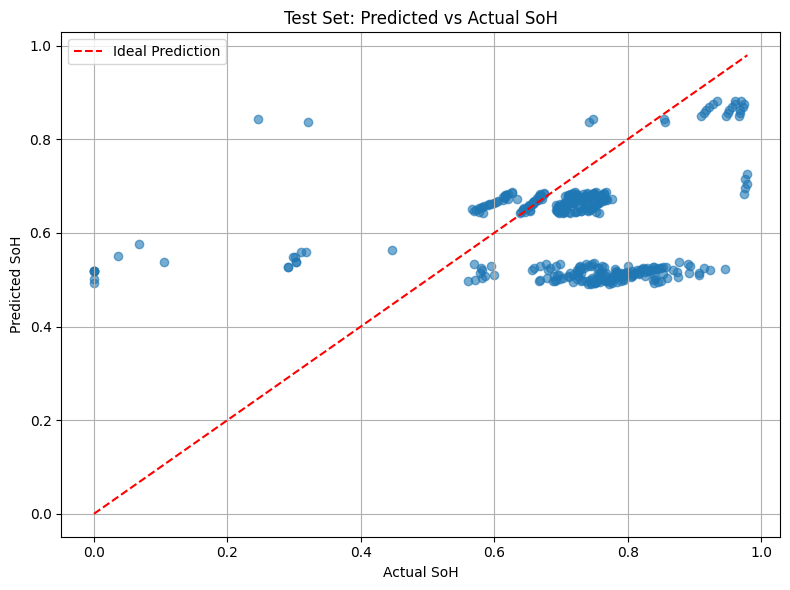

In [39]:
# Cell 14 – Predicted vs Actual SoH

plt.figure(figsize=(8, 6))

plt.scatter(
    y_true,
    y_pred,
    alpha=0.6
)

min_val = min(
    y_true.min(),
    y_pred.min()
)

max_val = max(
    y_true.max(),
    y_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Ideal Prediction"
)

plt.xlabel("Actual SoH")
plt.ylabel("Predicted SoH")

plt.title("Test Set: Predicted vs Actual SoH")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()